::: {.sb-downloads}
[Download this notebook](../downloads/solutions-build-a-decision-tree.ipynb){download="solutions-build-a-decision-tree.ipynb"}  
Data: [bl.txt](../downloads/data/bl.txt){download="bl.txt"}

Put the data files in a folder named `data` next to the notebook.
:::

::: {.sb-lesson-links}
[← Back to the exercises](../exercises/build-a-decision-tree.ipynb)
:::

::: {.callout-tip}
Try the exercises on your own first: you learn much more by searching than by reading a solution.
:::

## Importing libraries and dataset {#ex-importing-libraries-and-dataset}

0. Import the usual libraries

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import  OneHotEncoder, StandardScaler, LabelEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, f1_score, ConfusionMatrixDisplay, RocCurveDisplay, classification_report

import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio
# colour palette of the course
pio.templates["course"] = go.layout.Template(
    layout_colorway=["#3B47C4", "#E4572E", "#2E7D4F", "#F2C14E", "#8E7CC3", "#4BA3C3", "#111111", "#999999"]
)
pio.templates.default = "plotly_white+course"


1. Import the bl.txt dataset and display the first few lines.

In [ ]:
dataset = pd.read_csv("../data/bl.txt")

In [ ]:
dataset.head()

,balance,left_weight,left_distance,right_weight,right_distance
0,B,1,1,1,1
1,R,1,1,1,2
2,R,1,1,1,3
3,R,1,1,1,4
4,R,1,1,1,5


2. Display a table of descriptive statistics

In [ ]:
dataset.describe(include = 'all')

,balance,left_weight,left_distance,right_weight,right_distance
count,625,625.000000,625.000000,625.000000,625.000000
unique,3,NaN,NaN,NaN,NaN
top,R,NaN,NaN,NaN,NaN
freq,288,NaN,NaN,NaN,NaN
mean,NaN,3.000000,3.000000,3.000000,3.000000
std,NaN,1.415346,1.415346,1.415346,1.415346
min,NaN,1.000000,1.000000,1.000000,1.000000
25%,NaN,2.000000,2.000000,2.000000,2.000000
50%,NaN,3.000000,3.000000,3.000000,3.000000
75%,NaN,4.000000,4.000000,4.000000,4.000000


In [ ]:
dataset['balance'].value_counts()

balance
R    288
L    288
B     49
Name: count, dtype: int64

3. What is the dataset shape?

In [ ]:
dataset.shape

(625, 5)

## Preprocessing {#ex-preprocessing}

4. Separate the target variable "balance" into a Y object, and the explanatory variables into an X object.

In [ ]:
# Separate target variable Y from features X
print("Separating labels from features...")
target_variable = "balance"

X = dataset.drop(target_variable, axis = 1)
Y = dataset.loc[:,target_variable]

print("...Done.")
print()

print('Y : ')
print(Y.head())
print()
print('X :')
print(X.head())

Separating labels from features...
...Done.

Y : 
0    B
1    R
2    R
3    R
4    R
Name: balance, dtype: str

X :
   left_weight  left_distance  right_weight  right_distance
0            1              1             1               1
1            1              1             1               2
2            1              1             1               3
3            1              1             1               4
4            1              1             1               5


5. Split the data into a train set containing 70% of the data and a test set containing the rest, with random_state=42

In [ ]:
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size = 0.3, random_state=42, stratify = Y)

## Comparing Decision Trees: Gini or Entropy Criterion? {#ex-comparing-decision-trees-gini-or-entropy-criterion}

6. Create an instance of a 'DecisionTreeClassifier' with the GINI criterion, and fit it on the training data. Before that, do any preprocessing you think is necessary.

In [ ]:
### Preprocessings ###
# With a decision tree, there's no need to normalize the numerical variables !

# Encode label
encoder = LabelEncoder()
Y_train = encoder.fit_transform(Y_train)
Y_test = encoder.transform(Y_test)

In [ ]:
classifier_gini = DecisionTreeClassifier(criterion="gini")
classifier_gini.fit(X_train, Y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of sampl

7. Display your tree using `plot_tree` from [sklearn.tree](https://scikit-learn.org/stable/modules/generated/sklearn.tree.plot_tree.html)

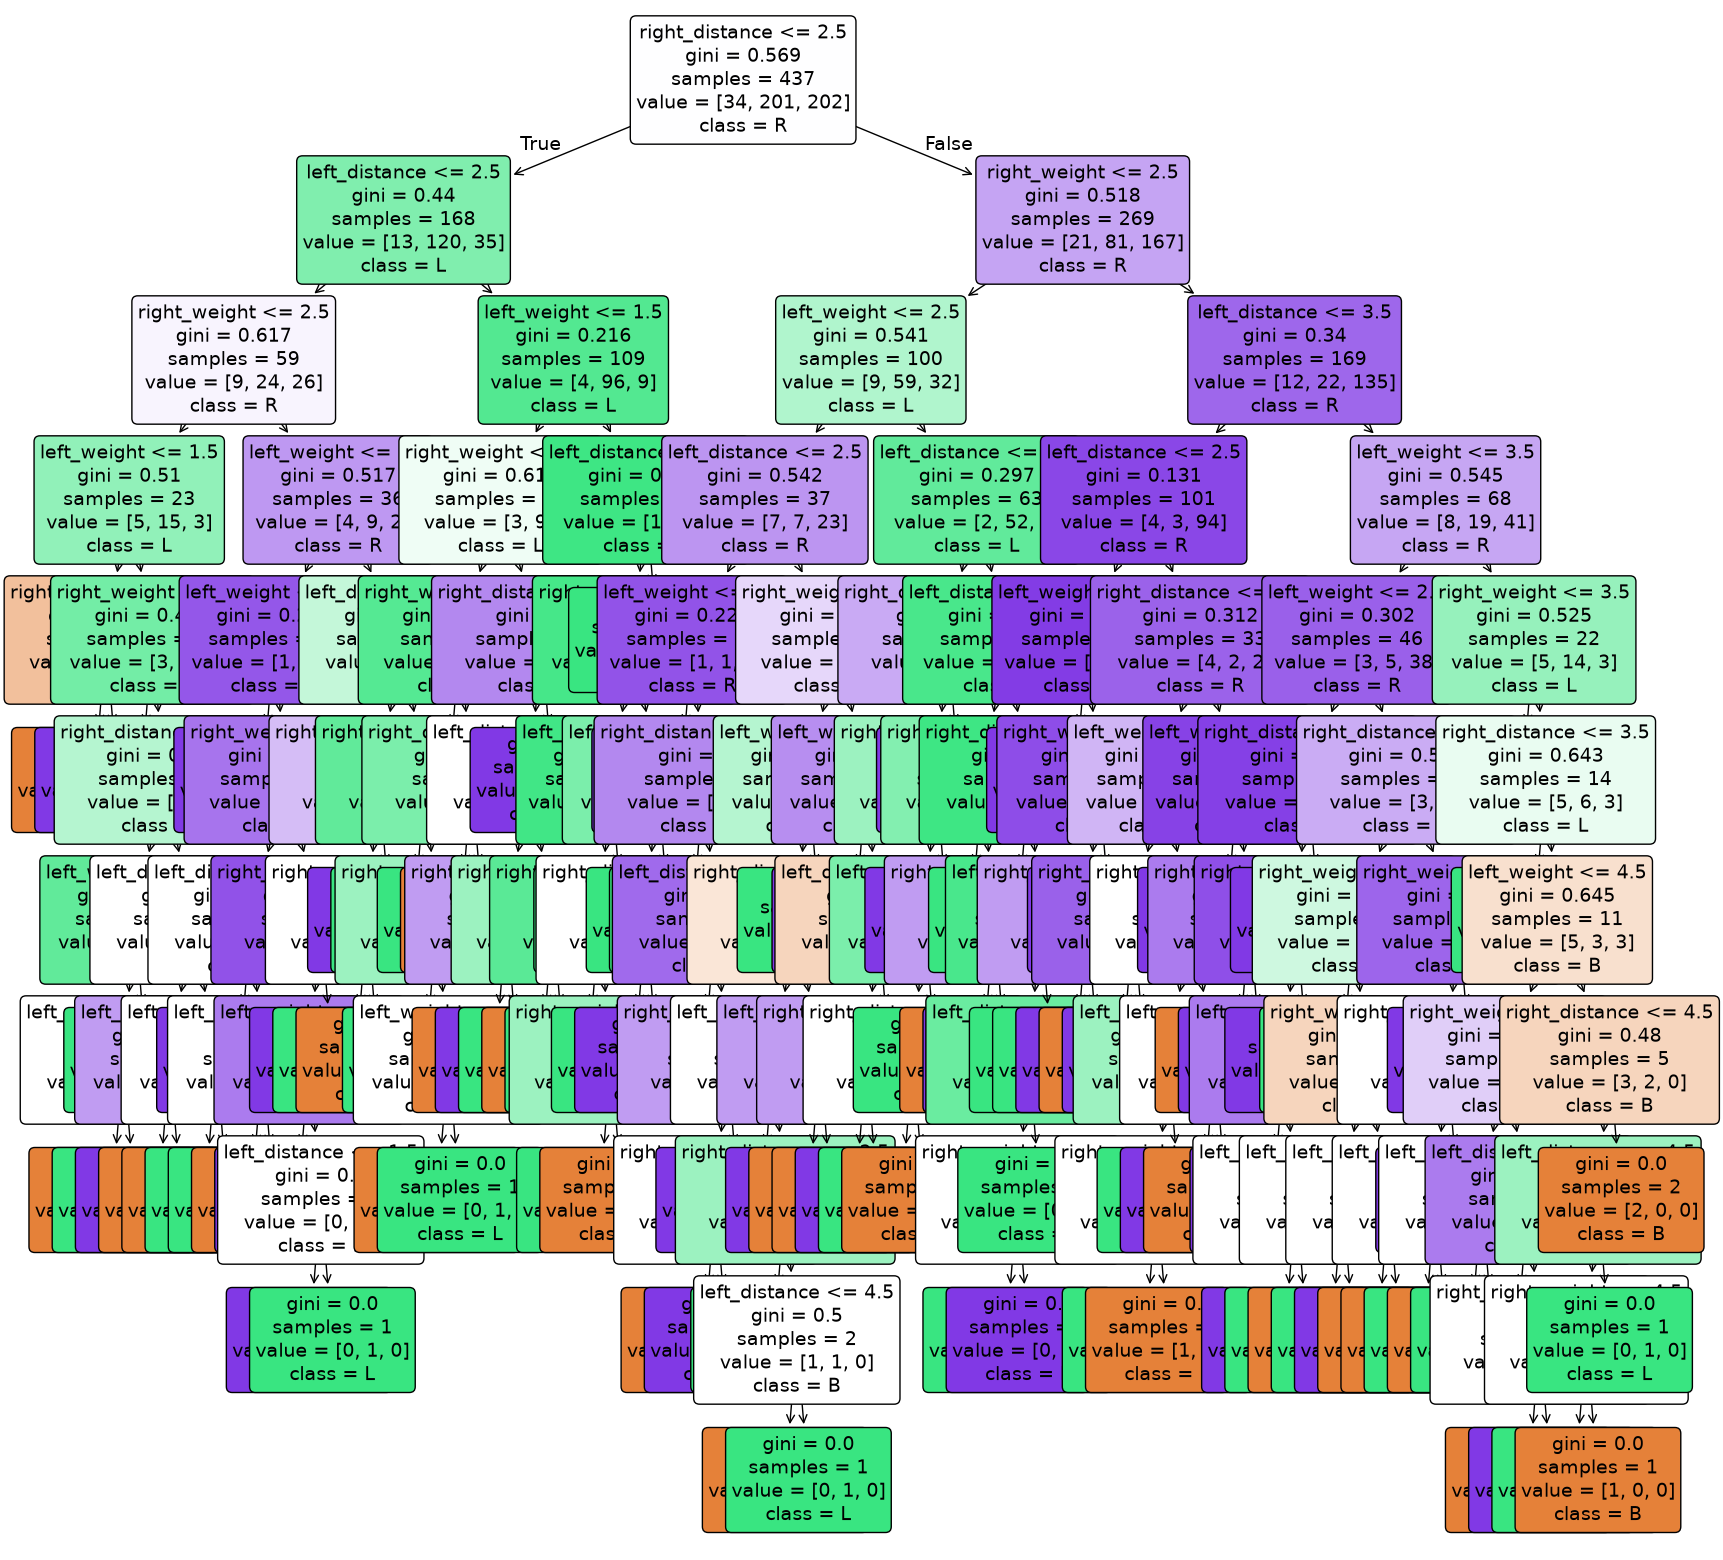

In [ ]:
from sklearn.tree import plot_tree

class_names = encoder.inverse_transform([0, 1, 2])

plt.figure(figsize=(20,20))
a = plot_tree(classifier_gini, 
              feature_names=X.columns, 
              class_names=class_names, 
              filled=True, 
              rounded=True, 
              fontsize=14)

8. Create an instance of a DecisionTreeClassifier using the entropy criterion.

In [ ]:
classifier_entropy = DecisionTreeClassifier(criterion="entropy")
classifier_entropy.fit(X_train,Y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'entropy'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of sa

9. Display the tree

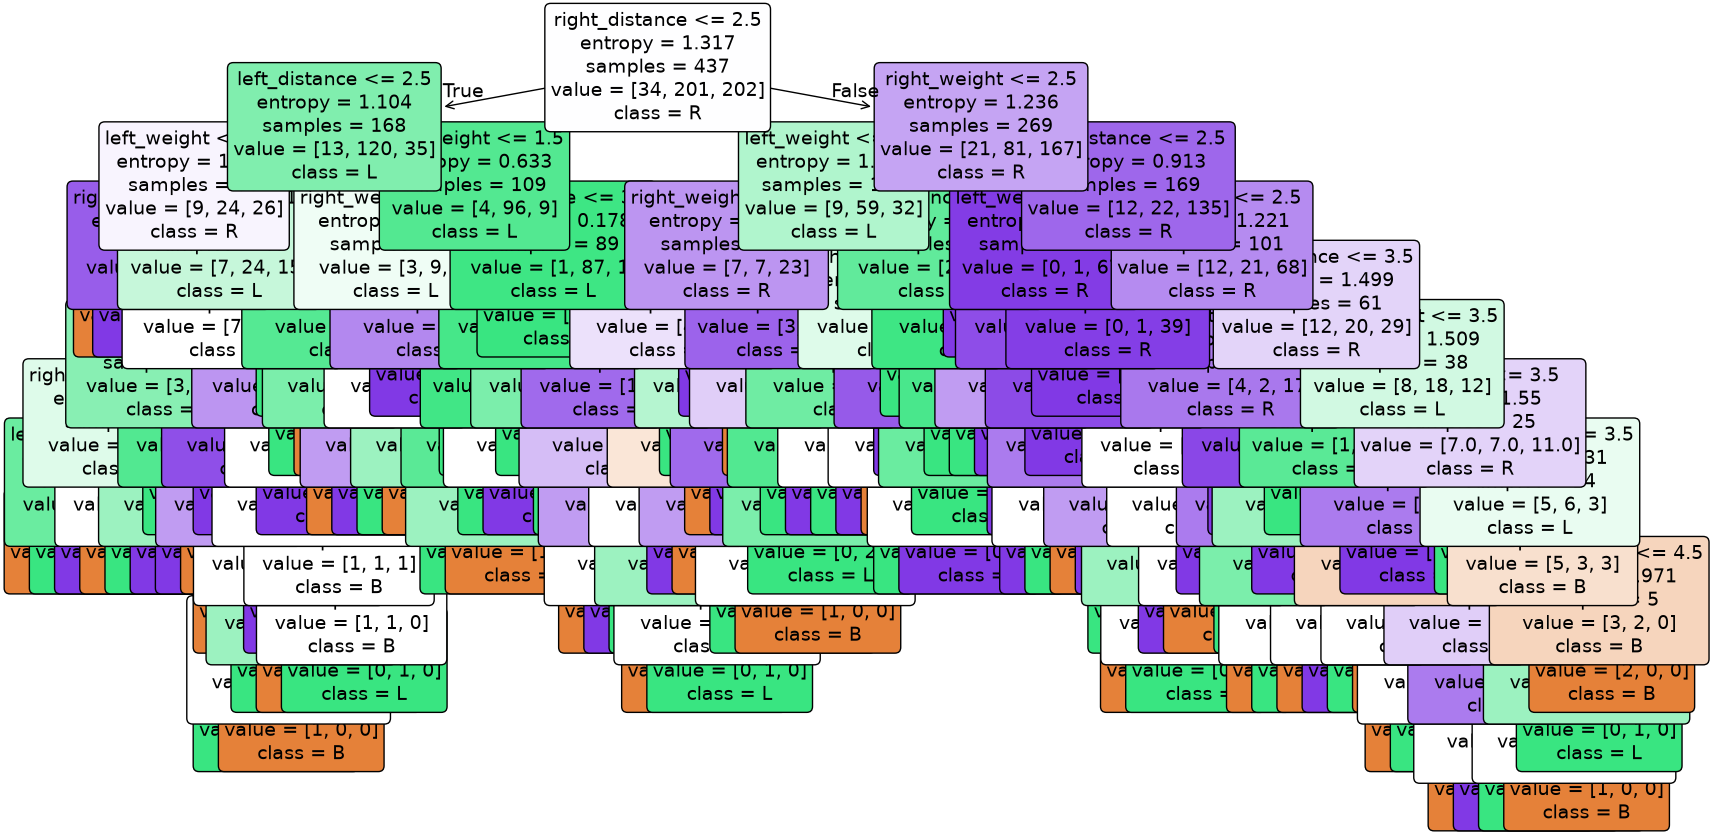

In [ ]:
plt.figure(figsize=(20,10))
a = plot_tree(classifier_entropy, 
              feature_names=X.columns, 
              class_names=class_names, 
              filled=True, 
              rounded=True, 
              fontsize=14)

10. Check whether the observation X_new = [4, 4, 3, 3] is classified as 'L' (left)

In [ ]:
X_new = pd.DataFrame(data = [[4,4,3,3]], columns = ["left_weight", "left_distance", "right_weight", "right_distance"])
classifier_entropy.predict(X_new)

array([1])

In [ ]:
encoder.inverse_transform([1])

array(['L'], dtype=object)

In [ ]:
classifier_gini.predict(X_new)

array([1])

11. Use the gini classifier to make predictions on the test set

In [ ]:
y_pred_gini = classifier_gini.predict(X_test)
y_pred_gini

array([2, 1, 0, 2, 1, 2, 2, 2, 0, 1, 2, 2, 0, 0, 2, 1, 1, 1, 1, 2, 2, 2,
       1, 2, 2, 0, 2, 0, 1, 2, 2, 1, 2, 1, 2, 2, 0, 2, 2, 2, 1, 0, 1, 1,
       1, 2, 2, 2, 2, 1, 0, 1, 1, 1, 2, 1, 2, 2, 2, 2, 1, 1, 2, 1, 2, 1,
       0, 1, 1, 0, 1, 1, 1, 2, 1, 1, 2, 1, 2, 1, 1, 1, 2, 2, 1, 1, 1, 2,
       1, 1, 1, 1, 1, 2, 1, 2, 1, 1, 2, 1, 2, 1, 1, 1, 1, 1, 1, 2, 0, 1,
       2, 1, 2, 1, 1, 0, 2, 0, 1, 2, 1, 1, 1, 2, 1, 2, 0, 2, 1, 0, 2, 1,
       2, 2, 0, 2, 1, 2, 1, 1, 1, 1, 2, 1, 1, 1, 2, 2, 0, 1, 2, 2, 0, 1,
       1, 2, 2, 2, 2, 2, 0, 1, 1, 2, 1, 2, 1, 1, 0, 1, 2, 0, 1, 1, 0, 1,
       2, 0, 1, 0, 2, 2, 1, 0, 1, 0, 0, 2])

12. Use the entropy classifier to make predictions on the test set

In [ ]:
y_pred_entropy = classifier_entropy.predict(X_test)
y_pred_entropy

array([2, 1, 2, 2, 1, 2, 2, 2, 0, 1, 2, 2, 0, 0, 2, 1, 1, 1, 1, 2, 2, 2,
       1, 2, 2, 0, 2, 0, 1, 2, 2, 1, 2, 1, 2, 2, 0, 2, 2, 2, 1, 0, 2, 1,
       1, 0, 2, 2, 2, 1, 0, 1, 1, 1, 2, 1, 2, 0, 1, 2, 1, 1, 2, 1, 2, 1,
       0, 1, 1, 0, 0, 1, 1, 2, 1, 1, 2, 1, 2, 1, 1, 1, 2, 2, 1, 1, 1, 2,
       0, 1, 1, 1, 1, 2, 1, 2, 1, 1, 2, 1, 2, 1, 1, 1, 1, 1, 1, 2, 0, 1,
       2, 1, 2, 1, 0, 2, 2, 0, 1, 2, 1, 1, 1, 2, 1, 2, 0, 2, 1, 0, 2, 1,
       2, 2, 0, 2, 1, 2, 1, 1, 1, 1, 2, 1, 1, 1, 2, 2, 0, 1, 2, 2, 0, 1,
       1, 2, 2, 2, 2, 2, 2, 1, 1, 2, 1, 2, 1, 0, 0, 1, 2, 1, 1, 1, 0, 1,
       2, 0, 1, 0, 2, 2, 1, 0, 1, 0, 0, 2])

13. Compare the predictions made by the gini and entropy classifiers: what proportion of predictions are identical?

You can either compare the predictions with a for loop over the indices of the observations, or simply loop over the two prediction vectors with the ```zip``` function.
To see what ```zip``` does, run:
```
A=[1,2,3]
B=["a","b","c"]

for a, b in zip(A,B):
  print(a,b)
```

The numbers in the solution will not necessarily be the ones you get, because of the random operations applied to your data.

In [ ]:
A=[1,2,3]
B=["a","b","c"]

for a, b in zip(A,B):
    print(a,b)

1 a
2 b
3 c


In [ ]:
count = 0

for i in range(0, len(y_pred_gini)):
  
  if y_pred_gini[i] != y_pred_entropy[i]:
    count+= 1

print("on the test set, there are {} examples that have different predictions from Gini and Entropy".format(count))
print("Which corresponds to a percentage of {}% ".format(np.round(count/len(y_pred_gini)*100, 3)))

on the test set, there are 12 examples that have different predictions from Gini and Entropy
Which corresponds to a percentage of 6.383% 


14. What's the accuracy of the gini classifier?

In [ ]:
classifier_gini.score(X_test, Y_test)

0.7393617021276596

15. What's the accuracy of the entropy classifier? 

In [ ]:
classifier_entropy.score(X_test, Y_test)

0.7553191489361702

16. Display the confusion matrix of the "entropy" model. What do you notice?

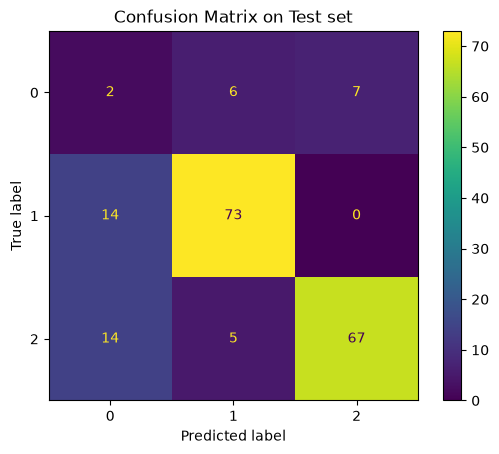

In [ ]:
# Visualize confusion matrices
_ , ax = plt.subplots() # Get subplot from matplotlib
ax.set(title="Confusion Matrix on Test set") # Set a title that we will add into ConfusionMatrixDisplay
ConfusionMatrixDisplay.from_estimator(classifier_entropy, X_test, Y_test, ax=ax) # ConfusionMatrixDisplay from sklearn
plt.show()



**--> Most errors correspond to examples of class 'B' that are misclassified as 'R' or 'L'**

17. Display the classification report of both models, on both the training and the test data. Do the models perform well? Do they overfit?

*Hint: have a look at scikit-learn's documentation about available metric functions* 😉

In [ ]:
print(classification_report(y_true = Y_test, y_pred=classifier_entropy.predict(X_test)))

              precision    recall  f1-score   support

           0       0.07      0.13      0.09        15
           1       0.87      0.84      0.85        87
           2       0.91      0.78      0.84        86

    accuracy                           0.76       188
   macro avg       0.61      0.58      0.59       188
weighted avg       0.82      0.76      0.79       188



In [ ]:
print(classification_report(y_true = Y_train, y_pred = classifier_entropy.predict(X_train)))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        34
           1       1.00      1.00      1.00       201
           2       1.00      1.00      1.00       202

    accuracy                           1.00       437
   macro avg       1.00      1.00      1.00       437
weighted avg       1.00      1.00      1.00       437



In [ ]:
print(classification_report(y_true = Y_test, y_pred = classifier_gini.predict(X_test)))

              precision    recall  f1-score   support

           0       0.04      0.07      0.05        15
           1       0.84      0.84      0.84        87
           2       0.89      0.76      0.82        86

    accuracy                           0.74       188
   macro avg       0.59      0.55      0.57       188
weighted avg       0.80      0.74      0.77       188



In [ ]:
print(classification_report(y_true = Y_train, y_pred = classifier_gini.predict(X_train)))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        34
           1       1.00      1.00      1.00       201
           2       1.00      1.00      1.00       202

    accuracy                           1.00       437
   macro avg       1.00      1.00      1.00       437
weighted avg       1.00      1.00      1.00       437



**Actually, both models are overfitting!**

## Fighting overfitting {#ex-fighting-overfitting}

18. How would you fight overfitting while still using decision tree classifiers? Try to find the set of hyperparameters that maximizes the performance of the model (using cross-validation on the training set), then evaluate it on the test set. Did the model perform better? Are there still ways to improve the model?

In [ ]:
rtc = DecisionTreeClassifier()
params = {'max_depth' : np.arange(1,10),
         'min_samples_split' : [2, 5, 10, 20]}

grid =  GridSearchCV(estimator=rtc, param_grid= params, cv = 10)
grid.fit(X_train, Y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",DecisionTreeClassifier()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': array([1, 2, ..., 6, 7, 8, 9]), 'min_samples_split': [2, 5, ...]}"
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",10
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity

In [ ]:
print('Classification report on train set:')
print(classification_report(Y_train, grid.best_estimator_.predict(X_train)))

Classification report on train set:
              precision    recall  f1-score   support

           0       0.67      0.06      0.11        34
           1       0.87      0.89      0.88       201
           2       0.82      0.93      0.87       202

    accuracy                           0.84       437
   macro avg       0.79      0.63      0.62       437
weighted avg       0.83      0.84      0.82       437



In [ ]:
print('Classification report on test set:')
print(classification_report(Y_test, grid.best_estimator_.predict(X_test)))

Classification report on test set:
              precision    recall  f1-score   support

           0       0.20      0.07      0.10        15
           1       0.80      0.83      0.81        87
           2       0.77      0.84      0.80        86

    accuracy                           0.77       188
   macro avg       0.59      0.58      0.57       188
weighted avg       0.74      0.77      0.75       188



**--> Overfitting has been reduced. We could now try more advanced techniques to improve the scores on new data a bit more.**

## Feature engineering {#ex-feature-engineering}

19. Try to create new variables to improve the model's performance. Redo the preprocessing, and train a new model with the gini criterion.

In [ ]:
dataset['left_prod'] = dataset['left_weight'] * dataset['left_distance']
dataset['right_prod'] = dataset['right_weight'] * dataset['right_distance']
dataset['balanced'] = dataset['right_prod'] - dataset['left_prod']

In [ ]:
# Separate target variable Y from features X
print("Separating labels from features...")
target_variable = "balance"

X = dataset.drop(target_variable, axis = 1)
Y = dataset.loc[:,target_variable]

print("...Done.")
print()

print('Y : ')
print(Y.head())
print()
print('X :')
print(X.head())

Separating labels from features...
...Done.

Y : 
0    B
1    R
2    R
3    R
4    R
Name: balance, dtype: str

X :
   left_weight  left_distance  right_weight  right_distance  left_prod  \
0            1              1             1               1          1   
1            1              1             1               2          1   
2            1              1             1               3          1   
3            1              1             1               4          1   
4            1              1             1               5          1   

   right_prod  balanced  
0           1         0  
1           2         1  
2           3         2  
3           4         3  
4           5         4  


In [ ]:
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size = 0.3, random_state=42, stratify = Y)

In [ ]:
classifier_gini = DecisionTreeClassifier(criterion="gini")
classifier_gini.fit(X_train, Y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of sampl

In [ ]:
print(classification_report(Y_train, classifier_gini.predict(X_train)))
print(classification_report(Y_test, classifier_gini.predict(X_test)))

              precision    recall  f1-score   support

           B       1.00      1.00      1.00        34
           L       1.00      1.00      1.00       201
           R       1.00      1.00      1.00       202

    accuracy                           1.00       437
   macro avg       1.00      1.00      1.00       437
weighted avg       1.00      1.00      1.00       437

              precision    recall  f1-score   support

           B       1.00      1.00      1.00        15
           L       1.00      1.00      1.00        87
           R       1.00      1.00      1.00        86

    accuracy                           1.00       188
   macro avg       1.00      1.00      1.00       188
weighted avg       1.00      1.00      1.00       188



The conclusion of this exercise: decision trees can be very high-variance models, able to capture non-linear links between the target variable and the explanatory variables, but they still have strong constraints on how they can model the data.
They split the space of the explanatory variables into "rectangles" (boxes), each carrying its own prediction for the target variable. 